g:\DIP Lab\Expt 8\Images
Image read successfully!
Otsu's calculated optimal threshold: 88.0


C:\Users\Admin\AppData\Local\Temp\ipykernel_20552\1457682836.py:40: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.ravel(), 256, [0, 256])


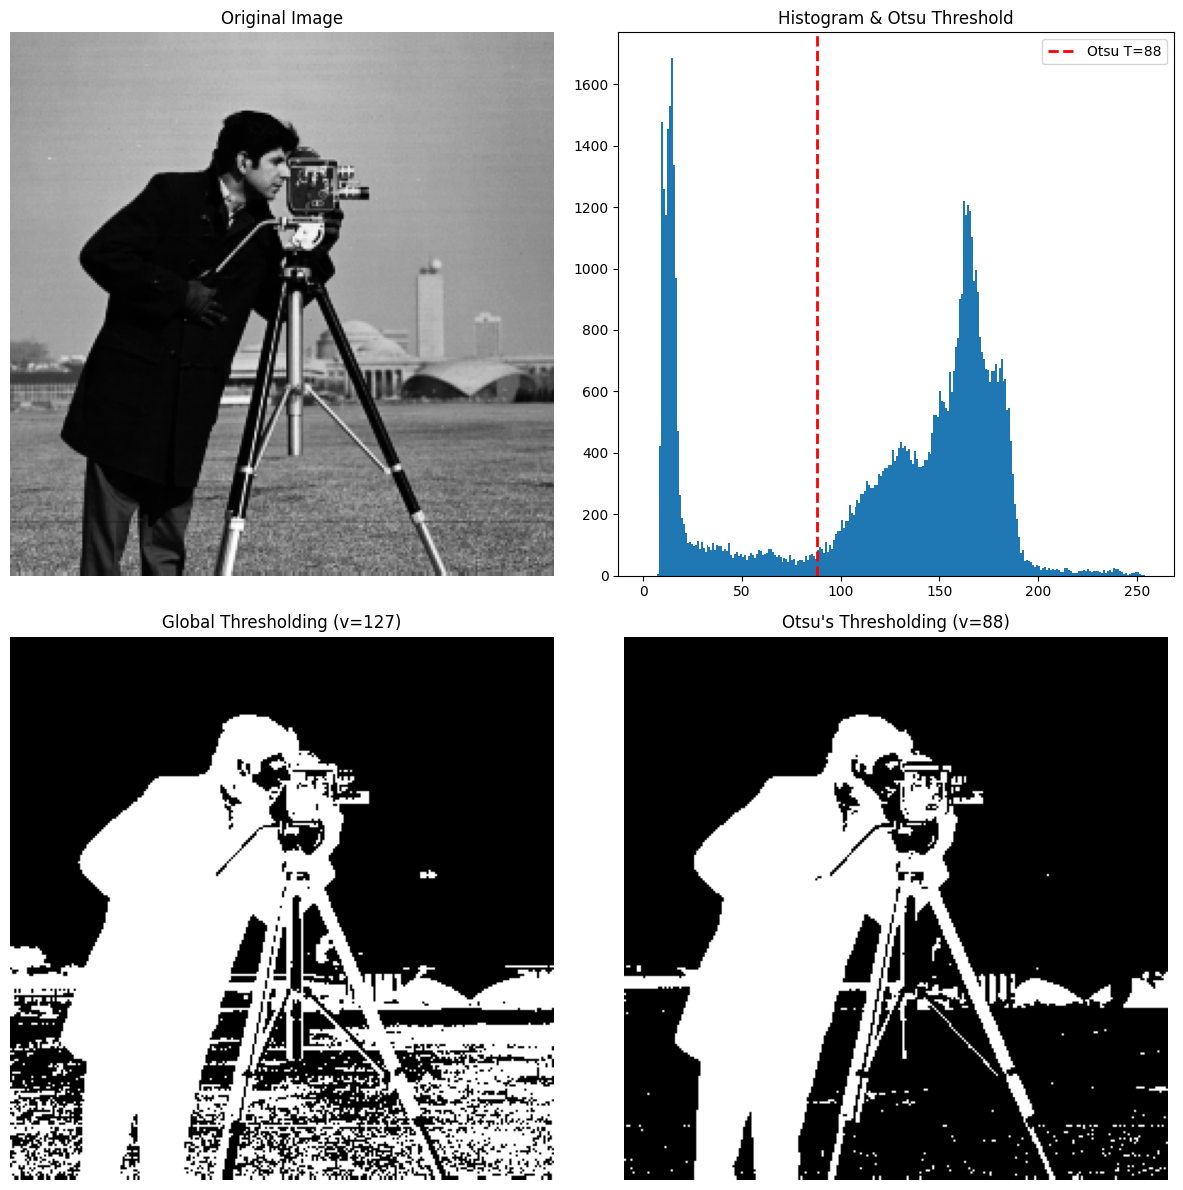

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

try:
    img = cv2.imread(image_path / "cameraman.tif", cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError("Image not found. Check the path.")
    print("Image read successfully!")
except Exception as e:
    print(f"Error loading image: {e}")

# --- Step 1: Simple Global Thresholding ---
# We pick an arbitrary value, say 127
ret, global_thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

# --- Step 2: Otsu's Binarization ---
# Pass the flag cv2.THRESH_OTSU. The threshold value is ignored (use 0).
ret_otsu, otsu_thresh = cv2.threshold(
img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
print(f"Otsu's calculated optimal threshold: {ret_otsu}")

# --- Step 4: Display Results & Histograms ---
plt.figure(figsize=(12, 12))

# 1. Original Noisy Image
plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# 2. Histogram
plt.subplot(2, 2, 2)
plt.hist(img.ravel(), 256, [0, 256])
plt.axvline(
x=ret_otsu,
color="r",
linestyle="dashed",
linewidth=2,
label=f"Otsu T={int(ret_otsu)}")
plt.title("Histogram & Otsu Threshold")
plt.legend()

# 3. Global Thresholding
plt.subplot(2, 2, 3)
plt.imshow(global_thresh, cmap="gray")
plt.title("Global Thresholding (v=127)")
plt.axis("off")

# 4. Otsu&#39;s Thresholding
plt.subplot(2, 2, 4)
plt.imshow(otsu_thresh, cmap="gray")
plt.title(f"Otsu's Thresholding (v={int(ret_otsu)})")
plt.axis("off")

plt.tight_layout()
plt.show()